# Phytochemical-Protein Interaction Prediction

## Task and reasoning

The primary task is to rank candidate human protein targets for each phytochemical using curated compound-protein associations as known positives. The available interaction table contains positives only: pairs absent from it are **unlabeled, not confirmed non-interactions**. Consequently, classifiers below are PU baselines trained against sampled unlabeled pairs, while validation/test ranking measures recovery of held-out curated positives against the full remaining target universe, not calibrated biological truth.

We first inspect the feature and label distributions, validate join keys and AAC normalization, then compare three classical PU baselines and a heterogeneous random walk. The notebook reports both five-fold compound-held-out (cold-start) evaluation and five-fold edge-held-out (transductive) evaluation. Random walk uses training compound-target positives only to avoid leaking held-out interaction edges.

## Dataset guide

- **Compound features:** 2,319 compounds represented by 2,048 binary ECFP4/Morgan radius-2 bits.
- **Target features:** 1,341 reviewed human proteins represented by 20 normalized amino-acid-composition (AAC) values, plus identifiers and names.
- **Known interactions:** 14,166 unique curated compound-protein pairs, all labeled positive.
- **Unlabeled universe:** 3,095,613 remaining pairs from the full compound x protein product; these are unmeasured/unrecorded, not negatives.
- **Herb-compound edges:** IMPPAT plant-to-compound associations, used to extend the compound-target graph for random walks.
- **Herb-compound-target paths:** Derived multi-hop hypotheses, not direct evidence that a herb engages a target in vivo.

Pair-model inputs concatenate compound ECFP4 and protein AAC features (2,068 values per pair). Their dimensions differ, so an elementwise product is undefined; concatenation is the transparent baseline.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_PATH = Path("datasets/imppat_hti_aac_ecfp4_v1")

compound_features = pd.read_csv(DATASET_PATH / "compound_features_ecfp4.csv")
target_features = pd.read_csv(DATASET_PATH / "target_features_aac.csv")
positive_pairs = pd.read_csv(DATASET_PATH / "compound_target_labeled.csv")
herb_compound_edges = pd.read_csv(DATASET_PATH / "herb_compound_edges.tsv", sep="\t")
herb_metadata = pd.read_csv(DATASET_PATH / "herbs.tsv", sep="\t")
compound_metadata = pd.read_csv(DATASET_PATH / "compounds.tsv", sep="\t")
herb_compound_target = pd.read_csv(DATASET_PATH / "herb_compound_target.csv")

fingerprint_columns = [column for column in compound_features if column.startswith("ecfp4_")]
aac_columns = [column for column in target_features if column.startswith("aac_")]

print("Loaded rows:")
display(pd.Series({
    "compounds": len(compound_features),
    "targets": len(target_features),
    "known positive pairs": len(positive_pairs),
    "herb-compound edges": len(herb_compound_edges),
    "herb-compound-target paths": len(herb_compound_target),
}, name="rows").to_frame())
print(f"Features per pair: {len(fingerprint_columns)} ECFP4 + {len(aac_columns)} AAC")

/home/sam-ruben-abraham/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Loaded rows:


,rows
compounds,2319
targets,1341
known positive pairs,14166
herb-compound edges,8396
herb-compound-target paths,126830


Features per pair: 2048 ECFP4 + 20 AAC


## Exploratory data analysis

Before fitting models, check identifiers, missingness, class semantics, feature ranges, and interaction-degree imbalance. The plots below summarize fingerprint sparsity, amino-acid composition, and positive interaction degrees.

In [2]:
# Basic schema, key, label, and feature-integrity checks.
summary = pd.DataFrame({
    "rows": [len(compound_features), len(target_features), len(positive_pairs)],
    "columns": [compound_features.shape[1], target_features.shape[1], positive_pairs.shape[1]],
    "duplicate primary keys": [
        compound_features["compound_id"].duplicated().sum(),
        target_features["protein_id"].duplicated().sum(),
        positive_pairs[["compound_id", "protein_id"]].duplicated().sum(),
    ],
    "missing values": [
        int(compound_features.isna().sum().sum()),
        int(target_features.isna().sum().sum()),
        int(positive_pairs[["compound_id", "protein_id", "label"]].isna().sum().sum()),
    ],
}, index=["compound features", "target features", "known interactions"])
display(summary)

print("Positive labels:", positive_pairs["label"].value_counts().to_dict())
print("Positive status:", positive_pairs["label_status"].value_counts().to_dict())
print("Compound IDs missing from features:", (~positive_pairs["compound_id"].isin(compound_features["compound_id"])).sum())
print("Protein IDs missing from features:", (~positive_pairs["protein_id"].isin(target_features["protein_id"])).sum())
print("AAC row-sum range:", target_features[aac_columns].sum(axis=1).min(), target_features[aac_columns].sum(axis=1).max())
print("Mean fingerprint bits set per compound:", compound_features[fingerprint_columns].to_numpy(dtype=np.float32).sum(axis=1).mean())

,rows,columns,duplicate primary keys,missing values
compound features,2319,2049,0,0
target features,1341,23,0,0
known interactions,14166,15,0,0


Positive labels: {1: 14166}
Positive status: {'IMPPAT_ASSOCIATION': 14166}
Compound IDs missing from features: 0
Protein IDs missing from features: 0
AAC row-sum range: 0.9999999999999984 1.0000000000000002
Mean fingerprint bits set per compound: 37.949978


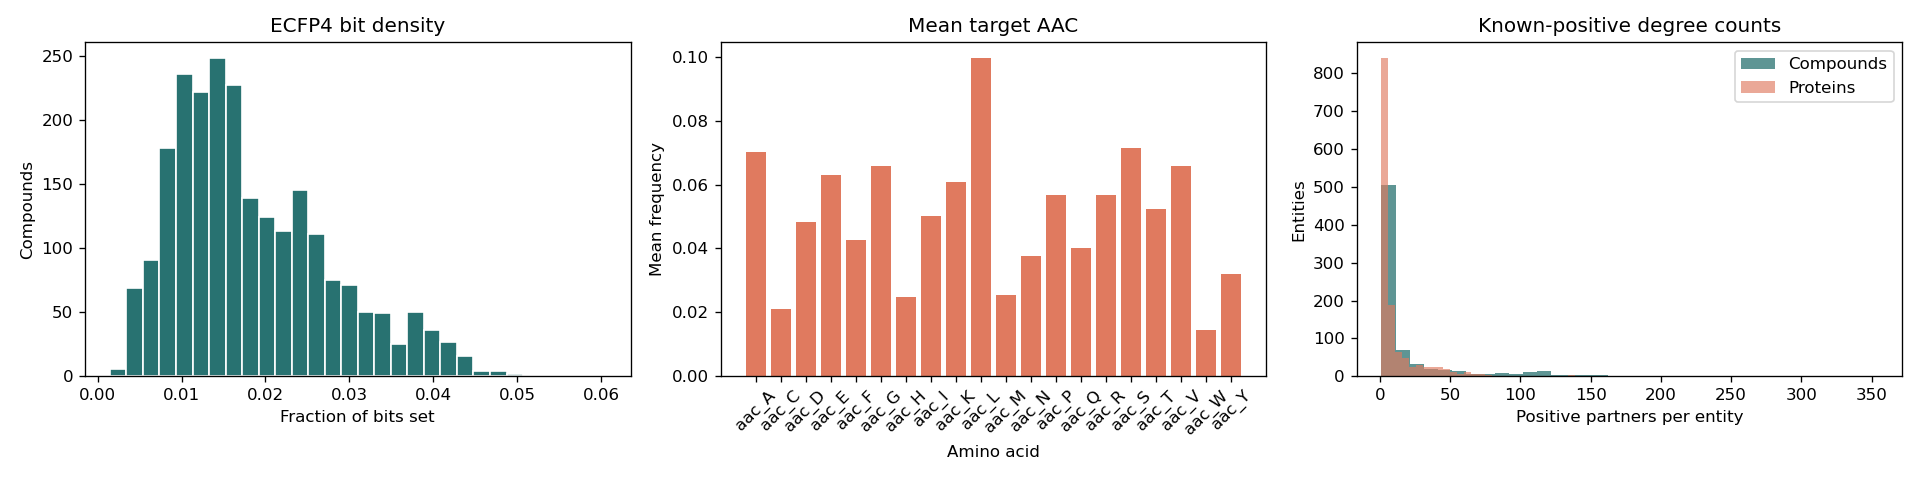

Positive interactions per compound (median/max): 5.0 354
Positive interactions per protein (median/max): 3.0 173
EDA note: these degrees describe recorded evidence, not biological selectivity or inactivity.


In [3]:
# EDA plots: fingerprints are sparse binary features; AAC rows are compositions.
from io import BytesIO
from IPython.display import Image
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure

fig = Figure(figsize=(16, 4))
FigureCanvasAgg(fig)
axes = fig.subplots(1, 3)

fingerprint_density = compound_features[fingerprint_columns].mean(axis=1)
axes[0].hist(fingerprint_density, bins=30, color="#287271", edgecolor="white")
axes[0].set(title="ECFP4 bit density", xlabel="Fraction of bits set", ylabel="Compounds")

aac_mean = target_features[aac_columns].mean()
axes[1].bar(aac_mean.index, aac_mean.values, color="#e07a5f", width=0.8)
axes[1].set(title="Mean target AAC", xlabel="Amino acid", ylabel="Mean frequency")
axes[1].tick_params(axis="x", rotation=45)

compound_degree = positive_pairs.groupby("compound_id").size()
protein_degree = positive_pairs.groupby("protein_id").size()
axes[2].hist(compound_degree, bins=35, alpha=0.75, label="Compounds", color="#287271")
axes[2].hist(protein_degree, bins=35, alpha=0.65, label="Proteins", color="#e07a5f")
axes[2].set(title="Known-positive degree counts", xlabel="Positive partners per entity", ylabel="Entities")
axes[2].legend()
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=120)
display(Image(data=image_buffer.getvalue()))

print("Positive interactions per compound (median/max):", compound_degree.median(), compound_degree.max())
print("Positive interactions per protein (median/max):", protein_degree.median(), protein_degree.max())
print("EDA note: these degrees describe recorded evidence, not biological selectivity or inactivity.")

## Splits, candidate sampling, and metrics

Compound-held-out evaluation uses the five fixed folds in `prep/folds_ct_compound.npz` (seed 42; validation share 0.15). Transductive evaluation uses the five fixed edge-held-out folds in `prep/folds_ct_edge.npz`, keeping the feature/node universe fixed while withholding positive links. Both use 10 sampled unlabeled pairs per positive for training and validation and 50 per positive for testing. Compound-target evaluation reports PR-AUC, filtered Hits@10/Hits@50/MRR, paired BPR loss, and positive/negative counts. Herb-target metrics are computed over derived paths by projecting compound-held-out splits through herb-compound edges; they are not direct herb-target evidence. Aggregation and target-popularity blend choices are selected on validation HT MRR only.

In [4]:
import json
from sklearn.metrics import average_precision_score
from sklearn.ensemble import IsolationForest
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

PREP_PATH = Path("prep")
PREP_META = json.loads((PREP_PATH / "meta.json").read_text())
PREP_FOLDS = np.load(PREP_PATH / "folds_ct_compound.npz")
FOLD_IDS = range(PREP_META["k"])
SEED = PREP_META["seed"]

compound_ids = np.asarray(PREP_META["compound_ids"])
protein_ids = np.asarray(PREP_META["target_ids"])
compound_feature_matrix = (
    compound_features.set_index("compound_id")[fingerprint_columns]
    .loc[compound_ids].astype(np.float32)
)
target_feature_matrix = (
    target_features.set_index("protein_id")[aac_columns]
    .loc[protein_ids].astype(np.float32)
)
compound_index = {compound_id: index for index, compound_id in enumerate(compound_ids)}
protein_index = {protein_id: index for index, protein_id in enumerate(protein_ids)}
known_interactions = np.zeros((len(compound_ids), len(protein_ids)), dtype=bool)
known_interactions[
    positive_pairs["compound_id"].map(compound_index).to_numpy(),
    positive_pairs["protein_id"].map(protein_index).to_numpy(),
] = True


def load_ct_fold(fold_index):
    """Load one prepared compound-target fold without changing its sampled pairs."""
    fold = {}
    for split in ("train", "val", "test"):
        part = {
            key: PREP_FOLDS[f"f{fold_index}_{split}_{key}"]
            for key in ("pos", "neg", "pair", "cols")
        }
        if part["cols"].size == 0:
            part["cols"] = None
        fold[split] = part
    return fold


def indexed_pairs_to_frame(index_pairs):
    return pd.DataFrame({
        "compound_id": compound_ids[index_pairs[0]],
        "protein_id": protein_ids[index_pairs[1]],
    })


def make_pair_features(pairs):
    """Concatenate ECFP4 and AAC vectors in pair-row order."""
    compounds = compound_feature_matrix.loc[pairs["compound_id"]].to_numpy(dtype=np.float32, copy=True)
    proteins = target_feature_matrix.loc[pairs["protein_id"]].to_numpy(dtype=np.float32, copy=True)
    return np.concatenate([compounds, proteins], axis=1)


def pr_auc(pos_scores, neg_scores):
    labels = np.r_[np.ones(len(pos_scores)), np.zeros(len(neg_scores))]
    return float(average_precision_score(labels, np.r_[pos_scores, neg_scores]))


def rank_summary(ranks, prefix=""):
    return {
        f"{prefix}Hits@10": float((ranks <= 10).mean()),
        f"{prefix}Hits@50": float((ranks <= 50).mean()),
        f"{prefix}MRR": float((1.0 / ranks).mean()),
    }


def filtered_ranks(scores, rows, cols, known, allowed_cols=None):
    true_scores = scores[rows, cols]
    keep = ~known[rows]
    if allowed_cols is not None:
        keep &= allowed_cols[None, :]
    higher = ((scores[rows] > true_scores[:, None]) & keep).sum(axis=1)
    ties = ((scores[rows] == true_scores[:, None]) & keep).sum(axis=1)
    return 1.0 + higher + 0.5 * ties


def score_link_set(scores, part, known, with_loss=True):
    """Match metrics.py link metrics for one prepared split using NumPy scores."""
    rows, cols = part["pos"]
    pos_scores = scores[rows, cols]
    neg_rows, neg_cols = part["neg"]
    neg_scores = scores[neg_rows, neg_cols]
    result = {"PR-AUC": pr_auc(pos_scores, neg_scores)}
    ranks = filtered_ranks(scores, rows, cols, known, part["cols"])
    result.update(rank_summary(ranks))
    if with_loss:
        paired_scores = scores[rows, part["pair"]]
        result["loss"] = float(np.logaddexp(0.0, -(pos_scores - paired_scores)).mean())
    else:
        result["loss"] = float("nan")
    result["n_pos"] = int(len(rows))
    result["n_neg"] = int(part["neg"].shape[1])
    return result


HERB_AGGREGATIONS = ["max", "mean", "top3", "noisy_or", "sum", "top50"]
POPULARITY_WEIGHTS = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
herb_ids = np.asarray(PREP_META["herb_ids"])
herb_compound_indices = [
    np.unique(
        herb_compound_edges.loc[
            herb_compound_edges["herb_id"] == herb_id, "compound_id"
        ].map(compound_index).dropna().to_numpy(dtype=np.int32)
    )
    for herb_id in herb_ids
]
if any(len(indices) == 0 for indices in herb_compound_indices):
    raise ValueError("Every prepared herb must map to at least one indexed compound.")


def project_ct_pairs_to_ht(ct_pairs):
    """Project compound-target pairs to derived herb-target paths."""
    compound_rows, target_cols = ct_pairs
    mask = np.zeros((len(herb_ids), len(protein_ids)), dtype=bool)
    for herb_row, member_compounds in enumerate(herb_compound_indices):
        selected = np.isin(compound_rows, member_compounds)
        mask[herb_row, target_cols[selected]] = True
    return mask


def build_ht_fold(ct_fold):
    """Build disjoint derived HT positives and projected sampled unlabeled pairs."""
    raw_positive = {
        split: project_ct_pairs_to_ht(ct_fold[split]["pos"])
        for split in ("train", "val", "test")
    }
    known = raw_positive["train"] | raw_positive["val"] | raw_positive["test"]
    positives = {
        "train": raw_positive["train"],
        "val": raw_positive["val"] & ~raw_positive["train"],
        "test": raw_positive["test"] & ~(raw_positive["train"] | raw_positive["val"]),
    }
    ht_fold = {}
    for split in ("train", "val", "test"):
        negative = project_ct_pairs_to_ht(ct_fold[split]["neg"]) & ~known
        ht_fold[split] = {"positives": positives[split], "negative": negative}
    return ht_fold, known


def herb_scores(ct_scores, how):
    """Aggregate compound-target scores into derived herb-target scores."""
    if how == "top50":
        top_k = min(50, ct_scores.shape[1])
        cutoff = np.partition(ct_scores, ct_scores.shape[1] - top_k, axis=1)[:, -top_k:]
        in_top = ct_scores >= cutoff.min(axis=1, keepdims=True)
    rows = []
    for indices in herb_compound_indices:
        block = ct_scores[indices]
        if how == "max":
            rows.append(block.max(axis=0))
        elif how == "mean":
            rows.append(block.mean(axis=0))
        elif how == "top3":
            rows.append(np.sort(block, axis=0)[-min(3, len(indices)):].mean(axis=0))
        elif how == "noisy_or":
            rows.append(np.logaddexp(0.0, block).sum(axis=0))
        elif how == "sum":
            rows.append(block.sum(axis=0))
        elif how == "top50":
            mean = block.mean(axis=0)
            tie_break = (mean - mean.min()) / (mean.max() - mean.min() + 1e-12) * 1e-3
            rows.append(in_top[indices].sum(axis=0) + tie_break)
        else:
            raise ValueError(f"Unknown herb aggregation: {how}")
    return np.stack(rows)


def tied_ranks(values):
    """Scale tied ranks to [0, 1], with larger values receiving larger ranks."""
    values = np.asarray(values)
    return (values[None, :] < values[:, None]).sum(axis=1) / max(len(values) - 1, 1)


def herb_rows_to_ranks(scores):
    return np.stack([tied_ranks(row) for row in scores])


def target_popularity(train_pos):
    degree = np.bincount(train_pos[1], minlength=len(protein_ids))
    return tied_ranks(degree)


def score_herb_set(herb_target_scores, positives, ht_known, ht_negative):
    """Score one part of the derived, not directly observed, herb-target paths."""
    herb_rows, target_cols = np.nonzero(positives)
    if len(herb_rows) == 0:
        return {
            "HT PR-AUC": float("nan"), "HT Hits@10": float("nan"),
            "HT Hits@50": float("nan"), "HT MRR": float("nan"), "HT n_pos": 0,
        }
    positive_scores = herb_target_scores[positives]
    negative_scores = herb_target_scores[ht_negative]
    ranks = filtered_ranks(herb_target_scores, herb_rows, target_cols, ht_known)
    return {
        "HT PR-AUC": pr_auc(positive_scores, negative_scores),
        **rank_summary(ranks, prefix="HT "),
        "HT n_pos": int(len(herb_rows)),
    }


def val_mrr(scores, part, known):
    """MRR for a compound-target split, for validation-only model selection."""
    rows, cols = part["pos"]
    ranks = filtered_ranks(scores, rows, cols, known, part["cols"])
    return float((1.0 / ranks).mean())


def val_ht_mrr(scores, part, known):
    rows, cols = np.nonzero(part["positives"])
    if len(rows) == 0:
        return float("nan")
    ranks = filtered_ranks(scores, rows, cols, known)
    return float((1.0 / ranks).mean())


def evaluate_herb_sets(ct_scores, ct_fold, ht_fold, ht_known):
    """Select aggregation and popularity blend on validation HT MRR, then score all splits."""
    if not ht_fold["val"]["positives"].any():
        raise ValueError("No validation herb-target paths remain after removing paths seen in training.")
    popularity = target_popularity(ct_fold["train"]["pos"])
    plain_how, plain_mrr = HERB_AGGREGATIONS[0], -1.0
    blend_how, blend_weight, blend_mrr = HERB_AGGREGATIONS[0], 0.0, -1.0
    for how in HERB_AGGREGATIONS:
        aggregate = herb_scores(ct_scores, how)
        mrr = val_ht_mrr(aggregate, ht_fold["val"], ht_known)
        if mrr > plain_mrr:
            plain_how, plain_mrr = how, mrr
        ranked = herb_rows_to_ranks(aggregate)
        for weight in POPULARITY_WEIGHTS:
            blended = (1.0 - weight) * ranked + weight * popularity[None, :]
            mrr = val_ht_mrr(blended, ht_fold["val"], ht_known)
            if mrr > blend_mrr:
                blend_how, blend_weight, blend_mrr = how, weight, mrr
    plain_scores = herb_scores(ct_scores, plain_how)
    blend_scores = (
        (1.0 - blend_weight) * herb_rows_to_ranks(herb_scores(ct_scores, blend_how))
        + blend_weight * popularity[None, :]
    )
    metrics = {}
    for split in ("train", "val", "test"):
        part = ht_fold[split]
        plain = score_herb_set(plain_scores, part["positives"], ht_known, part["negative"])
        blend = score_herb_set(blend_scores, part["positives"], ht_known, part["negative"])
        metrics[split] = {
            **blend,
            **{f"{key} (model only)": value for key, value in plain.items() if key != "HT n_pos"},
        }
    selection = {
        "HT aggregation": blend_how,
        "HT popularity weight": blend_weight,
        "HT aggregation (model only)": plain_how,
    }
    return metrics, selection


print("Prepared compound-target folds:", len(FOLD_IDS))
print("Fold 0 positive rows:", {split: int(load_ct_fold(0)[split]["pos"].shape[1]) for split in ("train", "val", "test")})

Prepared compound-target folds: 5
Fold 0 positive rows: {'train': 9168, 'val': 2164, 'test': 2834}


In [5]:
for fold_index in FOLD_IDS:
    prepared_fold = load_ct_fold(fold_index)
    compound_splits = [set(prepared_fold[split]["pos"][0]) for split in ("train", "val", "test")]
    assert not (compound_splits[0] & compound_splits[1])
    assert not (compound_splits[0] & compound_splits[2])
    assert not (compound_splits[1] & compound_splits[2])
    for split, ratio in PREP_META["neg_per_pos"].items():
        part = prepared_fold[split]
        assert part["neg"].shape[1] == ratio * part["pos"].shape[1]
        assert len(part["pair"]) == part["pos"].shape[1]
prepared_fold = load_ct_fold(0)
for split in ("train", "val", "test"):
    rows = prepared_fold[split]["pos"][0]
    print(f"Fold 0 {split}: {len(rows):,} positive links across {len(np.unique(rows)):,} compounds")
print("All prepared compound folds are disjoint and match their negative ratios.")

Fold 0 train: 9,168 positive links across 461 compounds
Fold 0 val: 2,164 positive links across 119 compounds
Fold 0 test: 2,834 positive links across 146 compounds
All prepared compound folds are disjoint and match their negative ratios.


## Build train and evaluation candidate sets

Training uses each fold's prepared 10:1 unlabeled-to-positive sample. Validation uses its prepared 10:1 sample, and test uses its prepared 50:1 sample. Ranking metrics still compare each positive against the full target universe, filtering other known positives for the same compound. The BPR loss uses the paired negative target saved for each positive.

In [6]:
def labeled_candidates(positives, background):
    positive_rows = positives[["compound_id", "protein_id"]].assign(label=1)
    background_rows = background[["compound_id", "protein_id"]].assign(label=0)
    return pd.concat([positive_rows, background_rows], ignore_index=True)


def build_fold_data(fold_index):
    """Build model inputs from the prepared positive and sampled-negative pairs."""
    fold = load_ct_fold(fold_index)
    for split in ("train", "val", "test"):
        fold[split]["positive_pairs"] = indexed_pairs_to_frame(fold[split]["pos"])
        fold[split]["negative_pairs"] = indexed_pairs_to_frame(fold[split]["neg"])
    train_candidates = labeled_candidates(
        fold["train"]["positive_pairs"], fold["train"]["negative_pairs"]
    )
    score_compound_indices = np.unique(np.concatenate([
        fold[split]["pos"][0] for split in ("train", "val", "test")
    ]))
    evaluation_pairs = pd.DataFrame({
        "compound_id": np.repeat(compound_ids[score_compound_indices], len(protein_ids)),
        "protein_id": np.tile(protein_ids, len(score_compound_indices)),
    })
    return {
        "fold": fold,
        "train_positive": fold["train"]["positive_pairs"],
        "train_negative": fold["train"]["negative_pairs"],
        "train_candidates": train_candidates,
        "validation_positive": fold["val"]["positive_pairs"],
        "evaluation_pairs": evaluation_pairs,
        "score_compound_indices": score_compound_indices,
    }


print("Prepared folds available for evaluation:", len(FOLD_IDS))

Prepared folds available for evaluation: 5


## Classical PU baselines

The Isolation Forest uses training-positive pair features to identify the most outlier-like candidates within the fold's prepared 10:1 training negatives; the bottom 20% become reliable-negative candidates, not ground-truth negatives. A tree classifier is iteratively refit after adding sampled candidates predicted below 0.01, for at most two rounds. XGBoost is used when installed; otherwise a scikit-learn histogram gradient-boosting model provides a compatible runnable baseline. Predictions are batched to keep peak memory bounded.

In [7]:
import gc
import importlib.util


def new_tree_classifier(random_state=SEED):
    if importlib.util.find_spec("xgboost") is not None:
        from xgboost import XGBClassifier
        return XGBClassifier(
            n_estimators=250, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, tree_method="hist",
            eval_metric="logloss", n_jobs=-1, random_state=random_state,
        )
    return HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=15, learning_rate=0.08,
        l2_regularization=1.0, random_state=random_state,
    )


def predict_positive_probability(model, pairs, batch_size=8192):
    probabilities = []
    for start in range(0, len(pairs), batch_size):
        batch = pairs.iloc[start:start + batch_size]
        probabilities.append(model.predict_proba(make_pair_features(batch))[:, 1])
    return np.concatenate(probabilities) if probabilities else np.array([])


print("Tree backend:", "XGBoost" if importlib.util.find_spec("xgboost") else "HistGradientBoosting fallback")

Tree backend: HistGradientBoosting fallback


## Elkan-Noto calibration and cost-sensitive SVM

Elkan-Noto estimates the fraction of true positives selected into the curated positive set from held-out positives, under a selected-completely-at-random assumption. That assumption is imperfect for literature-curated bioactivity, so calibrated values are relative scores, not probabilities of biological interaction. The biased SVM uses the documented positive-to-unlabeled universe ratio as its class-cost ratio.

In [8]:
# Per-seed Elkan-Noto calibration and cost-sensitive SVM fitting run below.

## Heterogeneous random walk with restart (RWR-H)

Build an undirected herb-compound-protein graph from all curated herb-compound edges and **training-positive** compound-protein edges only. The transition matrix is row-normalized; each compound seed performs a restart walk, and steady-state protein scores rank its candidate targets. This propagates graph proximity through shared herbs and compounds while withholding validation and test interaction edges.

In [9]:
from scipy.sparse import coo_matrix, diags


def build_heterogeneous_transition(train_edges):
    """Create row-stochastic transitions over herb, compound, and protein nodes."""
    herb_compound = herb_compound_edges[["herb_id", "compound_id"]].dropna().drop_duplicates()
    herb_compound = herb_compound[
        herb_compound["compound_id"].isin(compound_ids)
        & herb_compound["herb_id"].astype(str).ne("")
    ]
    compound_protein = train_edges[["compound_id", "protein_id"]].drop_duplicates()

    herbs = herb_compound["herb_id"].astype(str).unique()
    compounds = compound_ids.astype(str)
    proteins = protein_ids.astype(str)
    nodes = ([ ("herb", value) for value in herbs ]
             + [ ("compound", value) for value in compounds ]
             + [ ("protein", value) for value in proteins ])
    node_index = {node: index for index, node in enumerate(nodes)}

    left = []
    right = []
    for herb_id, compound_id in herb_compound.itertuples(index=False, name=None):
        left.append(node_index[("herb", str(herb_id))])
        right.append(node_index[("compound", str(compound_id))])
    for compound_id, protein_id in compound_protein.itertuples(index=False, name=None):
        left.append(node_index[("compound", str(compound_id))])
        right.append(node_index[("protein", str(protein_id))])

    row = np.asarray(left + right, dtype=np.int32)
    column = np.asarray(right + left, dtype=np.int32)
    adjacency = coo_matrix(
        (np.ones(len(row), dtype=np.float32), (row, column)),
        shape=(len(nodes), len(nodes)),
    ).tocsr()
    adjacency.data[:] = 1.0
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inverse_degree = np.divide(1.0, degree, out=np.zeros_like(degree), where=degree > 0)
    transition = diags(inverse_degree) @ adjacency
    return transition.tocsr(), node_index


def random_walk_with_restart(transition, seed_index, restart_probability=0.15, tolerance=1e-10, max_iterations=200):
    """Return the converged stationary probability vector for one seed node."""
    seed = np.zeros(transition.shape[0], dtype=np.float64)
    seed[seed_index] = 1.0
    probabilities = seed.copy()
    for _ in range(max_iterations):
        updated = (1.0 - restart_probability) * (transition.T @ probabilities) + restart_probability * seed
        if np.linalg.norm(updated - probabilities, ord=1) < tolerance:
            return updated
        probabilities = updated
    return probabilities


def predict_rwr_scores(transition, node_index, candidates):
    scores = np.zeros(len(candidates), dtype=np.float64)
    for compound_id, candidate_indices in candidates.groupby("compound_id", sort=False).groups.items():
        seed_index = node_index[("compound", compound_id)]
        steady_state = random_walk_with_restart(transition, seed_index)
        protein_indices = [
            node_index[("protein", protein_id)]
            for protein_id in candidates.loc[candidate_indices, "protein_id"]
        ]
        scores[np.asarray(list(candidate_indices), dtype=int)] = steady_state[np.asarray(protein_indices, dtype=np.int32)]
    return scores


def evaluate_fold(fold_index):
    global pu_tree_model, elkan_model, biased_svm, selection_probability, rwr_transition, rwr_node_index
    seed = SEED + fold_index
    data = build_fold_data(fold_index)
    fold = data["fold"]
    ht_fold, ht_known = build_ht_fold(fold)
    train_positive = data["train_positive"]
    train_negative = data["train_negative"]
    train_candidates = data["train_candidates"]
    validation_positive = data["validation_positive"]

    reliable_negative_pool = train_negative
    positive_features = make_pair_features(train_positive)
    isolation_forest = IsolationForest(
        n_estimators=150, max_samples=min(256, len(positive_features)),
        contamination="auto", random_state=seed, n_jobs=-1,
    ).fit(positive_features)
    reliable_scores = np.concatenate([
        isolation_forest.decision_function(make_pair_features(reliable_negative_pool.iloc[start:start + 8192]))
        for start in range(0, len(reliable_negative_pool), 8192)
    ])
    reliable_negative_mask = reliable_scores <= np.quantile(reliable_scores, 0.20)
    reliable_negatives = reliable_negative_pool.loc[reliable_negative_mask].reset_index(drop=True)
    del positive_features, isolation_forest, reliable_scores
    gc.collect()

    pu_train_pairs = pd.concat([train_positive, reliable_negatives], ignore_index=True)
    pu_train_labels = np.r_[np.ones(len(train_positive)), np.zeros(len(reliable_negatives))]
    pu_tree_model = new_tree_classifier(random_state=seed)
    pu_tree_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)
    remaining_background = reliable_negative_pool.loc[~reliable_negative_mask].reset_index(drop=True)
    for iteration in range(2):
        remaining_scores = predict_positive_probability(pu_tree_model, remaining_background)
        expansion_mask = remaining_scores < 0.01
        newly_added = remaining_background.loc[expansion_mask].reset_index(drop=True)
        if newly_added.empty:
            break
        pu_train_pairs = pd.concat([pu_train_pairs, newly_added], ignore_index=True)
        pu_train_labels = np.r_[pu_train_labels, np.zeros(len(newly_added))]
        pu_tree_model = new_tree_classifier(random_state=seed + iteration + 1)
        pu_tree_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)
        remaining_background = remaining_background.loc[~expansion_mask].reset_index(drop=True)
    evaluation_pairs = data["evaluation_pairs"]
    two_step_scores = predict_positive_probability(pu_tree_model, evaluation_pairs)

    elkan_model = new_tree_classifier(random_state=seed + 10)
    elkan_model.fit(make_pair_features(train_candidates), train_candidates["label"].to_numpy())
    validation_positive_scores = predict_positive_probability(elkan_model, validation_positive)
    selection_probability = max(float(validation_positive_scores.mean()), 1e-6)
    elkan_scores = np.minimum(
        1.0, predict_positive_probability(elkan_model, evaluation_pairs) / selection_probability
    )

    full_unlabeled_to_positive_ratio = 3_095_613 / 14_166
    svm_train_pairs = train_candidates[["compound_id", "protein_id"]]
    biased_svm = make_pipeline(
        StandardScaler(with_mean=False),
        LinearSVC(
            C=1.0,
            class_weight={0: 1.0, 1: full_unlabeled_to_positive_ratio},
            dual="auto", max_iter=5000, random_state=seed,
        ),
    )
    biased_svm.fit(make_pair_features(svm_train_pairs), train_candidates["label"].to_numpy())
    svm_scores = []
    for start in range(0, len(evaluation_pairs), 8192):
        batch = evaluation_pairs.iloc[start:start + 8192]
        svm_scores.append(biased_svm.decision_function(make_pair_features(batch)))
    svm_scores = np.concatenate(svm_scores)

    rwr_transition, rwr_node_index = build_heterogeneous_transition(train_positive)
    rwr_scores = predict_rwr_scores(rwr_transition, rwr_node_index, evaluation_pairs)
    predictions = {
        "Two-step PU": two_step_scores,
        "Elkan-Noto": elkan_scores,
        "Cost-sensitive SVM": svm_scores,
        "RWR-H": rwr_scores,
    }
    score_matrices = {}
    for model_name, scores in predictions.items():
        full_scores = np.zeros((len(compound_ids), len(protein_ids)), dtype=np.float32)
        full_scores[data["score_compound_indices"]] = np.asarray(scores).reshape(
            len(data["score_compound_indices"]), len(protein_ids)
        )
        score_matrices[model_name] = full_scores
    seed_results = []
    selection_results = []
    for model_name, scores in score_matrices.items():
        for split_name in ("train", "val", "test"):
            metrics = score_link_set(scores, fold[split_name], known_interactions)
            seed_results.extend(
                {"fold": fold_index, "split": split_name, "model": model_name, "metric": metric, "value": value}
                for metric, value in metrics.items()
            )
        ht_metrics, ht_selection = evaluate_herb_sets(scores, fold, ht_fold, ht_known)
        for split_name, metrics in ht_metrics.items():
            seed_results.extend(
                {"fold": fold_index, "split": split_name, "model": model_name, "metric": metric, "value": value}
                for metric, value in metrics.items()
            )
        selection_results.append({
            "fold": fold_index, "model": model_name, **ht_selection,
        })
    model_ensembles.append({
        "seed": seed,
        "two_step": pu_tree_model,
        "elkan": elkan_model,
        "selection_probability": selection_probability,
        "svm": biased_svm,
        "rwr_transition": rwr_transition,
        "rwr_node_index": rwr_node_index,
    })
    return seed_results, selection_results


model_ensembles = []
seed_metric_rows = []
ht_selection_rows = []
for fold_index in FOLD_IDS:
    print(f"Evaluating prepared compound-held-out fold {fold_index}...")
    fold_metrics, fold_selection = evaluate_fold(fold_index)
    seed_metric_rows.extend(fold_metrics)
    ht_selection_rows.extend(fold_selection)

seed_metrics = pd.DataFrame(seed_metric_rows)
metric_summary = (
    seed_metrics.groupby(["split", "model", "metric"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)
metric_summary["mean ± std"] = metric_summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
)
display(metric_summary.pivot(index=["split", "model"], columns="metric", values="mean ± std"))
display(pd.DataFrame(ht_selection_rows).groupby("model").agg(lambda values: ", ".join(map(str, sorted(set(values))))))
print(f"Reported values are mean ± sample standard deviation across {len(FOLD_IDS)} prepared folds.")

Evaluating prepared compound-held-out fold 0...
Evaluating prepared compound-held-out fold 1...
Evaluating prepared compound-held-out fold 2...
Evaluating prepared compound-held-out fold 3...
Evaluating prepared compound-held-out fold 4...


metric                         HT Hits@10 HT Hits@10 (model only)  \
split model                                                         
test  Cost-sensitive SVM  0.1373 ± 0.0432         0.0076 ± 0.0050   
      Elkan-Noto          0.1376 ± 0.0401         0.0701 ± 0.0251   
      RWR-H               0.1393 ± 0.0420         0.1376 ± 0.0368   
      Two-step PU         0.1383 ± 0.0401         0.0462 ± 0.0101   
train Cost-sensitive SVM  0.4426 ± 0.0163         0.0116 ± 0.0025   
      Elkan-Noto          0.4438 ± 0.0247         0.2694 ± 0.0095   
      RWR-H               0.5870 ± 0.0971         0.6995 ± 0.1346   
      Two-step PU         0.4465 ± 0.0205         0.1922 ± 0.0220   
val   Cost-sensitive SVM  0.1612 ± 0.0833         0.0144 ± 0.0078   
      Elkan-Noto          0.1642 ± 0.0810         0.0887 ± 0.0580   
      RWR-H               0.1689 ± 0.0746         0.1600 ± 0.0641   
      Two-step PU         0.1627 ± 0.0817         0.0547 ± 0.0166   

metric                         HT Hits@50 HT Hits@50 (model only)  \
split model                                                         
test  Cost-sensitive SVM  0.3054 ± 0.0566         0.0456 ± 0.0125   
      Elkan-Noto          0.3015 ± 0.0607         0.1702 ± 0.0414   
      RWR-H               0.3095 ± 0.0547         0.3043 ± 0.0530   
      Two-step PU         0.3043 ± 0.0611         0.1477 ± 0.0324   
train Cost-sensitive SVM  0.6388 ± 0.0108         0.0480 ± 0.0045   
      Elkan-Noto          0.6358 ± 0.0147         0.4100 ± 0.0154   
      RWR-H               0.7688 ± 0.0754         0.8629 ± 0.0878   
      Two-step PU         0.6396 ± 0.0122         0.3413 ± 0.0195   
val   Cost-sensitive SVM  0.3279 ± 0.0759         0.0476 ± 0.0143   
      Elkan-Noto          0.3249 ± 0.0772         0.1971 ± 0.0708   
      RWR-H               0.3375 ± 0.0744         0.3375 ± 0.0695   
      Two-step PU         0.3262 ± 0.0774         0.1595 ± 0.0505   

metric                             HT MRR HT MRR (model only)  \
split model                                                     
test  Cost-sensitive SVM  0.0662 ± 0.0174     0.0069 ± 0.0018   
      Elkan-Noto          0.0670 ± 0.0157     0.0373 ± 0.0130   
      RWR-H               0.0666 ± 0.0165     0.0611 ± 0.0106   
      Two-step PU         0.0656 ± 0.0159     0.0257 ± 0.0043   
train Cost-sensitive SVM  0.3176 ± 0.0240     0.0084 ± 0.0010   
      Elkan-Noto          0.3248 ± 0.0191     0.1856 ± 0.0105   
      RWR-H               0.4605 ± 0.1119     0.5442 ± 0.1325   
      Two-step PU         0.3248 ± 0.0184     0.1194 ± 0.0173   
val   Cost-sensitive SVM  0.0906 ± 0.0436     0.0091 ± 0.0022   
      Elkan-Noto          0.0905 ± 0.0437     0.0527 ± 0.0327   
      RWR-H               0.0948 ± 0.0450     0.0829 ± 0.0349   
      Two-step PU         0.0905 ± 0.0437     0.0329 ± 0.0128   

metric                          HT PR-AUC HT PR-AUC (model only)  \
split model                                                        
test  Cost-sensitive SVM  0.1343 ± 0.0288        0.0571 ± 0.0288   
      Elkan-Noto          0.1187 ± 0.0422        0.0641 ± 0.0342   
      RWR-H               0.1322 ± 0.0237        0.1243 ± 0.0627   
      Two-step PU         0.1355 ± 0.0277        0.0664 ± 0.0225   
train Cost-sensitive SVM  0.7873 ± 0.0088        0.3626 ± 0.0150   
      Elkan-Noto          0.7086 ± 0.1594        0.4729 ± 0.0843   
      RWR-H               0.8620 ± 0.0309        0.8154 ± 0.2556   
      Two-step PU         0.7913 ± 0.0098        0.4669 ± 0.1114   
val   Cost-sensitive SVM  0.2332 ± 0.0893        0.0650 ± 0.0129   
      Elkan-Noto          0.2174 ± 0.1073        0.1083 ± 0.0771   
      RWR-H               0.2360 ± 0.0888        0.2197 ± 0.1098   
      Two-step PU         0.2322 ± 0.0887        0.0911 ± 0.0247   

metric                                  HT n_pos          Hits@10  \
split model                                                         
test  Cost-sensitive SVM    2501.2000 ± 952.1529  0.0217 ± 0.004

,fold,HT aggregation,HT popularity weight,HT aggregation (model only)
model,,,,
Cost-sensitive SVM,"0, 1, 2, 3, 4",max,"0.9, 1.0",max
Elkan-Noto,"0, 1, 2, 3, 4","max, mean","0.1, 0.75, 0.9, 1.0","mean, top50"
RWR-H,"0, 1, 2, 3, 4","max, mean, top3, top50","0.0, 0.25, 0.5, 0.9","mean, noisy_or, top3"
Two-step PU,"0, 1, 2, 3, 4","max, top50","0.9, 1.0","max, mean"


Reported values are mean ± sample standard deviation across 5 prepared folds.


## Compare methods and rank candidate targets

Prepared train, validation, and test compound-target links are scored with their fold-specific sampled unlabeled pairs. Herb-target metrics summarize derived herb-compound-target paths, with validation-only selection among six aggregation methods and target-popularity blend weights. These HT results are indirect path-based hypotheses, not direct herb-target evidence. The prediction helper ranks remaining unrecorded targets for a selected compound and returns hypotheses, not confirmed interactions.

In [10]:
test_metric_results = (
    seed_metrics.loc[seed_metrics["split"] == "test"]
    .pivot_table(index="model", columns="metric", values="value", aggfunc="mean")
    .sort_values("PR-AUC", ascending=False)
)
display(test_metric_results)


herb_compound_lookup = (
    herb_compound_edges[["compound_id", "herb_id", "plant_part"]]
    .dropna(subset=["compound_id", "herb_id"])
    .merge(
        compound_metadata[["compound_id", "Phytochemical name_standardised"]],
        on="compound_id", how="left", validate="many_to_one",
    )
    .merge(
        herb_metadata[["herb_id", "botanical_name", "Indian_Medicinal_plant"]],
        on="herb_id", how="left", validate="many_to_one",
    )
)
herb_compound_lookup["herb_association"] = herb_compound_lookup.apply(
    lambda row: (
        f"{row['botanical_name']} ({row['Indian_Medicinal_plant']}; {row['herb_id']}; "
        f"part: {row['plant_part'] if pd.notna(row['plant_part']) else 'unspecified'})"
    ),
    axis=1,
)
compound_herb_summary = (
    herb_compound_lookup.groupby("compound_id", as_index=False)
    .agg(
        phytochemical_name=("Phytochemical name_standardised", "first"),
        herb_associations=(
            "herb_association",
            lambda values: "; ".join(sorted(set(values))),
        ),
    )
)

def rank_unlabeled_targets(compound_id, model_name="Elkan-Noto", top_k=20):
    """Rank unrecorded targets and trace each phytochemical to its associated herbs."""
    if compound_id not in compound_feature_matrix.index:
        raise KeyError(f"Unknown compound_id: {compound_id}")
    known_targets = set(positive_pairs.loc[
        positive_pairs["compound_id"] == compound_id, "protein_id"
    ])
    candidates = pd.DataFrame({"compound_id": compound_id, "protein_id": protein_ids})
    candidates = candidates.loc[~candidates["protein_id"].isin(known_targets)].reset_index(drop=True)

    calibrated_estimate = None
    if model_name == "Two-step PU":
        scores = np.mean([
            predict_positive_probability(models["two_step"], candidates)
            for models in model_ensembles
        ], axis=0)
    elif model_name == "Elkan-Noto":
        calibrated_scores = [
            np.minimum(
                1.0,
                predict_positive_probability(models["elkan"], candidates)
                / models["selection_probability"],
            )
            for models in model_ensembles
        ]
        scores = np.mean(calibrated_scores, axis=0)
        calibrated_estimate = scores
    elif model_name == "Cost-sensitive SVM":
        score_parts = []
        for models in model_ensembles:
            model_scores = []
            for start in range(0, len(candidates), 8192):
                batch = candidates.iloc[start:start + 8192]
                model_scores.append(models["svm"].decision_function(make_pair_features(batch)))
            score_parts.append(np.concatenate(model_scores))
        scores = np.mean(score_parts, axis=0)
    elif model_name == "RWR-H":
        scores = np.mean([
            predict_rwr_scores(models["rwr_transition"], models["rwr_node_index"], candidates)
            for models in model_ensembles
        ], axis=0)
    else:
        raise ValueError("Unknown model_name; choose Two-step PU, Elkan-Noto, Cost-sensitive SVM, or RWR-H")

    predictions = candidates.assign(score=scores)
    if calibrated_estimate is not None:
        predictions["PU_estimate_capped"] = calibrated_estimate
    predictions = predictions.merge(
        target_features[["protein_id", "uniprot_accession", "protein_name"]],
        on="protein_id", how="left", validate="many_to_one",
    )
    predictions = predictions.merge(
        compound_herb_summary, on="compound_id", how="left", validate="many_to_one",
    )
    predictions["herb_associations"] = predictions["herb_associations"].fillna(
        "No mapped herb association"
    )
    return predictions.sort_values("score", ascending=False).head(top_k).reset_index(drop=True)


example_compound_id = positive_pairs["compound_id"].iloc[0]
print("Example ranked unrecorded targets for:", example_compound_id)
display(rank_unlabeled_targets(example_compound_id, model_name="Elkan-Noto", top_k=10))

metric,HT Hits@10,HT Hits@10 (model only),HT Hits@50,HT Hits@50 (model only),HT MRR,HT MRR (model only),HT PR-AUC,HT PR-AUC (model only),HT n_pos,Hits@10,Hits@50,MRR,PR-AUC,loss,n_neg,n_pos
model,,,,,,,,,,,,,,,,
RWR-H,0.139271,0.137631,0.309453,0.304281,0.066607,0.061128,0.132163,0.124318,2501.2,0.135606,0.384088,0.064795,0.119535,0.692967,141660.0,2833.2
Elkan-Noto,0.137560,0.070063,0.301485,0.170159,0.066982,0.037308,0.118667,0.064092,2501.2,0.047650,0.302343,0.023601,0.047009,0.592406,141660.0,2833.2
Two-step PU,0.138325,0.046180,0.304262,0.147659,0.065560,0.025655,0.135472,0.066389,2501.2,0.114500,0.295427,0.053903,0.032356,0.668207,141660.0,2833.2
Cost-sensitive SVM,0.137339,0.007628,0.305408,0.045574,0.066215,0.006887,0.134331,0.057066,2501.2,0.021743,0.046379,0.011331,0.023168,0.679660,141660.0,2833.2


Example ranked unrecorded targets for: IMPPAT3_PHYID000002


,compound_id,protein_id,score,PU_estimate_capped,uniprot_accession,protein_name,phytochemical_name,herb_associations
0,IMPPAT3_PHYID000002,UNIPROT:Q9UNA4,1.0,1.0,Q9UNA4,DNA polymerase iota,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
1,IMPPAT3_PHYID000002,UNIPROT:P21728,1.0,1.0,P21728,Dopamine receptor D1,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
2,IMPPAT3_PHYID000002,UNIPROT:P35354,1.0,1.0,P35354,Prostaglandin G/H synthase 2,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
3,IMPPAT3_PHYID000002,UNIPROT:O75496,1.0,1.0,O75496,Geminin,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
4,IMPPAT3_PHYID000002,UNIPROT:P08908,1.0,1.0,P08908,5-hydroxytryptamine receptor 1A,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
5,IMPPAT3_PHYID000002,UNIPROT:P10636,1.0,1.0,P10636,Microtubule-associated protein tau,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
6,IMPPAT3_PHYID000002,UNIPROT:Q16236,1.0,1.0,Q16236,Nuclear factor erythroid 2-related factor 2,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
7,IMPPAT3_PHYID000002,UNIPROT:Q03181,1.0,1.0,Q03181,Peroxisome proliferator-activated receptor delta,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
8,IMPPAT3_PHYID000002,UNIPROT:P00918,1.0,1.0,P00918,Carbonic anhydrase 2,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...
9,IMPPAT3_PHYID000002,UNIPROT:P00915,1.0,1.0,P00915,Carbonic anhydrase 1,D-Glucose,Acorus calamus (Acorus calamus; IMPPAT_PLANT:I...


## Interpretation and limitations

The notebook reports two evaluation protocols: compound-held-out folds in `prep/folds_ct_compound.npz` for cold-start evaluation, and edge-held-out folds in `prep/folds_ct_edge.npz` for transductive evaluation. Each preserves prepared train/validation/test positive and sampled-unlabeled pairs. Results are averaged over five folds.

Evaluation follows `metrics.py`: compound-target PR-AUC, filtered Hits@10/Hits@50/MRR, paired BPR loss, and positive/negative counts; plus the corresponding herb-target metrics for derived herb-compound-target paths. Herb-target positives are projected from each CT split, duplicate paths are assigned to the earliest split, and projected sampled unlabeled pairs supply PR-AUC comparisons after known HT paths are removed. Aggregations and popularity weights are picked using validation HT MRR, not test results. These are path-based metrics, not direct herb-target evidence. Other known positive targets for a compound are filtered out of ranking competitors. The prepared CT negative ratios are 10:1 for training and validation and 50:1 for test. The local environment does not include XGBoost, so the tree-based cells use scikit-learn `HistGradientBoostingClassifier`. Elkan-Noto additionally assumes positive selection is approximately random, which curated literature data does not guarantee.

Use `rank_unlabeled_targets(compound_id, model_name=..., top_k=...)` to inspect candidates for a compound. The output includes the standardized phytochemical name and herb associations (with herb ID and reported plant part), traced through the herb-compound edges. These are derived herb-compound-target paths, not direct herb-target evidence. Scores prioritize experiments; neither a high rank nor a derived path establishes direct binding, in-vivo target engagement, efficacy, or clinical benefit.

## Transductive edge-held-out evaluation

This run keeps the compound and target feature/node universe fixed and partitions positive compound-target edges instead of compounds. It uses `prep/folds_ct_edge.npz`; each compound may have training and held-out links in the same fold. The four models and sampled-unlabeled ratios match the compound-held-out run. Ranking filters all other curated positive targets for a compound while retaining the specific held-out target being ranked.


In [ ]:
TRANS_FOLDS = np.load(PREP_PATH / "folds_ct_edge.npz")


def load_transductive_fold(fold_index):
    fold = {}
    for split in ("train", "val", "test"):
        part = {
            key: TRANS_FOLDS[f"f{fold_index}_{split}_{key}"]
            for key in ("pos", "neg", "pair", "cols")
        }
        if part["cols"].size == 0:
            part["cols"] = None
        fold[split] = part
    return fold


def score_transductive_link_set(scores, part):
    rows, cols = part["pos"]
    pos_scores = scores[rows, cols]
    neg_rows, neg_cols = part["neg"]
    neg_scores = scores[neg_rows, neg_cols]
    ranks = np.empty(len(rows), dtype=np.float64)
    for row in np.unique(rows):
        positions = np.flatnonzero(rows == row)
        competitors = np.broadcast_to(
            ~known_interactions[row], (len(positions), len(protein_ids))
        ).copy()
        competitors[np.arange(len(positions)), cols[positions]] = False
        true_scores = scores[row, cols[positions]]
        higher = (scores[row][None, :] > true_scores[:, None]) & competitors
        tied = (scores[row][None, :] == true_scores[:, None]) & competitors
        ranks[positions] = 1.0 + higher.sum(axis=1) + 0.5 * tied.sum(axis=1)
    paired_scores = scores[rows, part["pair"]]
    return {
        "PR-AUC": pr_auc(pos_scores, neg_scores),
        **rank_summary(ranks),
        "loss": float(np.logaddexp(0.0, -(pos_scores - paired_scores)).mean()),
        "n_pos": int(len(rows)),
        "n_neg": int(len(neg_rows)),
    }


def evaluate_transductive_fold(fold_index):
    seed = SEED + fold_index
    fold = load_transductive_fold(fold_index)
    train_positive = indexed_pairs_to_frame(fold["train"]["pos"])
    train_negative = indexed_pairs_to_frame(fold["train"]["neg"])
    train_candidates = labeled_candidates(train_positive, train_negative)
    validation_positive = indexed_pairs_to_frame(fold["val"]["pos"])
    evaluation_pairs = pd.DataFrame({
        "compound_id": np.repeat(compound_ids, len(protein_ids)),
        "protein_id": np.tile(protein_ids, len(compound_ids)),
    })

    positive_features = make_pair_features(train_positive)
    isolation_forest = IsolationForest(
        n_estimators=150, max_samples=min(256, len(positive_features)),
        contamination="auto", random_state=seed, n_jobs=-1,
    ).fit(positive_features)
    reliable_scores = np.concatenate([
        isolation_forest.decision_function(make_pair_features(train_negative.iloc[start:start + 8192]))
        for start in range(0, len(train_negative), 8192)
    ])
    reliable_mask = reliable_scores <= np.quantile(reliable_scores, 0.20)
    pu_train_pairs = pd.concat(
        [train_positive, train_negative.loc[reliable_mask]], ignore_index=True
    )
    pu_train_labels = np.r_[np.ones(len(train_positive)), np.zeros(reliable_mask.sum())]
    del positive_features, isolation_forest, reliable_scores
    gc.collect()
    pu_model = new_tree_classifier(random_state=seed)
    pu_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)
    remaining_background = train_negative.loc[~reliable_mask].reset_index(drop=True)
    for iteration in range(2):
        expansion = predict_positive_probability(pu_model, remaining_background) < 0.01
        newly_added = remaining_background.loc[expansion].reset_index(drop=True)
        if newly_added.empty:
            break
        pu_train_pairs = pd.concat([pu_train_pairs, newly_added], ignore_index=True)
        pu_train_labels = np.r_[pu_train_labels, np.zeros(len(newly_added))]
        pu_model = new_tree_classifier(random_state=seed + iteration + 1)
        pu_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)
        remaining_background = remaining_background.loc[~expansion].reset_index(drop=True)
    pu_scores = predict_positive_probability(pu_model, evaluation_pairs)

    elkan_model = new_tree_classifier(random_state=seed + 10)
    elkan_model.fit(make_pair_features(train_candidates), train_candidates["label"].to_numpy())
    selection_probability = max(
        float(predict_positive_probability(elkan_model, validation_positive).mean()), 1e-6
    )
    elkan_scores = np.minimum(
        1.0, predict_positive_probability(elkan_model, evaluation_pairs) / selection_probability
    )

    full_unlabeled_to_positive_ratio = 3_095_613 / 14_166
    svm_model = make_pipeline(
        StandardScaler(with_mean=False),
        LinearSVC(
            C=1.0, class_weight={0: 1.0, 1: full_unlabeled_to_positive_ratio},
            dual="auto", max_iter=5000, random_state=seed,
        ),
    )
    svm_model.fit(
        make_pair_features(train_candidates[["compound_id", "protein_id"]]),
        train_candidates["label"].to_numpy(),
    )
    svm_scores = np.concatenate([
        svm_model.decision_function(make_pair_features(evaluation_pairs.iloc[start:start + 8192]))
        for start in range(0, len(evaluation_pairs), 8192)
    ])

    transition, node_index = build_heterogeneous_transition(train_positive)
    rwr_scores = predict_rwr_scores(transition, node_index, evaluation_pairs)
    predictions = {
        "Two-step PU": pu_scores,
        "Elkan-Noto": elkan_scores,
        "Cost-sensitive SVM": svm_scores,
        "RWR-H": rwr_scores,
    }
    score_matrices = {
        name: values.reshape(len(compound_ids), len(protein_ids))
        for name, values in predictions.items()
    }
    results = []
    for model_name, score_matrix in score_matrices.items():
        for split_name in ("val", "test"):
            metrics = score_transductive_link_set(score_matrix, fold[split_name])
            results.extend(
                {"fold": fold_index, "split": split_name, "model": model_name,
                 "metric": metric, "value": value}
                for metric, value in metrics.items()
            )
    del score_matrices, predictions, evaluation_pairs
    gc.collect()
    return results


for fold_index in FOLD_IDS:
    edge_fold = load_transductive_fold(fold_index)
    split_edges = [set(map(tuple, edge_fold[split]["pos"].T)) for split in ("train", "val", "test")]
    assert not (split_edges[0] & split_edges[1])
    assert not (split_edges[0] & split_edges[2])
    assert not (split_edges[1] & split_edges[2])
    train_compounds = set(edge_fold["train"]["pos"][0])
    test_compounds = set(edge_fold["test"]["pos"][0])
    assert train_compounds & test_compounds
    for split_name, ratio in PREP_META["neg_per_pos"].items():
        part = edge_fold[split_name]
        assert part["neg"].shape[1] == ratio * part["pos"].shape[1]

transductive_metric_rows = []
for fold_index in FOLD_IDS:
    print(f"Evaluating transductive edge-held-out fold {fold_index}...")
    transductive_metric_rows.extend(evaluate_transductive_fold(fold_index))

transductive_metrics = pd.DataFrame(transductive_metric_rows)
transductive_test_summary = (
    transductive_metrics.loc[transductive_metrics["split"].isin(["val", "test"])]
    .groupby(["split", "model", "metric"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)
transductive_test_summary["mean ± std"] = transductive_test_summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
)
display(transductive_test_summary.pivot(
    index=["split", "model"], columns="metric", values="mean ± std"
))
print("Transductive ranking uses the fixed compound/target universe and filters other known positive links.")
print(f"Reported values are mean ± sample standard deviation across {len(FOLD_IDS)} edge folds.")